In [1]:
from mt_rent_statement import *

### Load data

In [2]:
start='2026-08-01'
end='2026-08-31'
dfT=load_tenancies('all_tenancies.xls')
dfAll=load_data(start,end)
dfAll.head(3)

Reading file: C:\Work\Mat\property\data\property\checked\AUG2026_codedAndCategorised.xlsx


C:\Users\mathe\anaconda3\envs\Python36\lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat
2026-08-01,60-83-71 00558156,-465.00,REPAIRS_AND_MAINTENANCE,Alhambra Road M Tucker SC,NaN,NaN,ServiceCharge,NaN
2026-08-01,60-83-71 00558156,-98.38,EQUIPMENT,Costco Costco Wholesale #117,NaN,NaN,PersonalExpense,EatingOut
2026-08-01,60-83-71 00558156,925.00,REVENUE,R Cowie FLAT 14. PO4 0RF,F141214ALH,NaN,OurRent,NaN


### Rent Statement

In [3]:
paidinadvancelist = []
inarrearslist = []
dfRs=get_rent_statement(dfAll, dfT, start, end, inarrearslist, paidinadvancelist)
dfRs=dfRs.round(0)
#dfRs.sort_values(by=['Net'], ascending=False).style.apply(custom_style, axis=1)
#dfRs.sort_values(by=['Bills'], ascending=True).style.apply(custom_style, axis=1)
#dfRs.style.apply(custom_style, axis=1)
num_cols = dfRs.select_dtypes(include=["number"]).columns
dfRs.style.format({c: "{:.0f}" for c in num_cols}).apply(custom_style, axis=1)

,Tenant,Agent,Received,Bills,Mortgage,Net,Status
Property,,,,,,,
321 London Rd,,,0,0,0,0,
Flat 1 - 321 London Rd,Ruksana Akter Chowdhury (09/08/2023),0,775,0,-392,383,Paid
Flat 2 - 321 London Rd,Mr Jake Bishop (16/03/2026),0,875,0,-376,499,Paid
Flat 3 - 321 London Rd,Harold Lingard-Kay & Stephen Cressdee (24/04/2026),0,1000,0,-315,685,Paid
Flat 4 - 321 London Rd,Chloe Freshney & Harry Aldingtons (31/01/2023),0,800,0,-392,408,Paid
169 Fawcett Rd,,,0,0,0,0,
Flat 1 - 169 Fawcett Rd,Miss Letisha Lowe (14/11/2025),0,825,0,-353,472,Paid
Flat 2 - 169 Fawcett Rd,Matthew Granil (31/07/2024),0,775,0,-313,462,Paid
Flat 3 - 169 Fawcett Rd,,,0,-825,-378,-1203,Empty


Notes:
- 

Remarks:
- each 0.25% increase in rates causes an increase in costs of £750 - ideally we need rates back at 4.5% to pay £22500 p/m
- find out what happens when a business loans money to another and it is not repaid - ask Chatgpt
- things should improve in March - by then hopefully empties rented, paid in advance start to pay again in March


### Income/Expenditure per Property

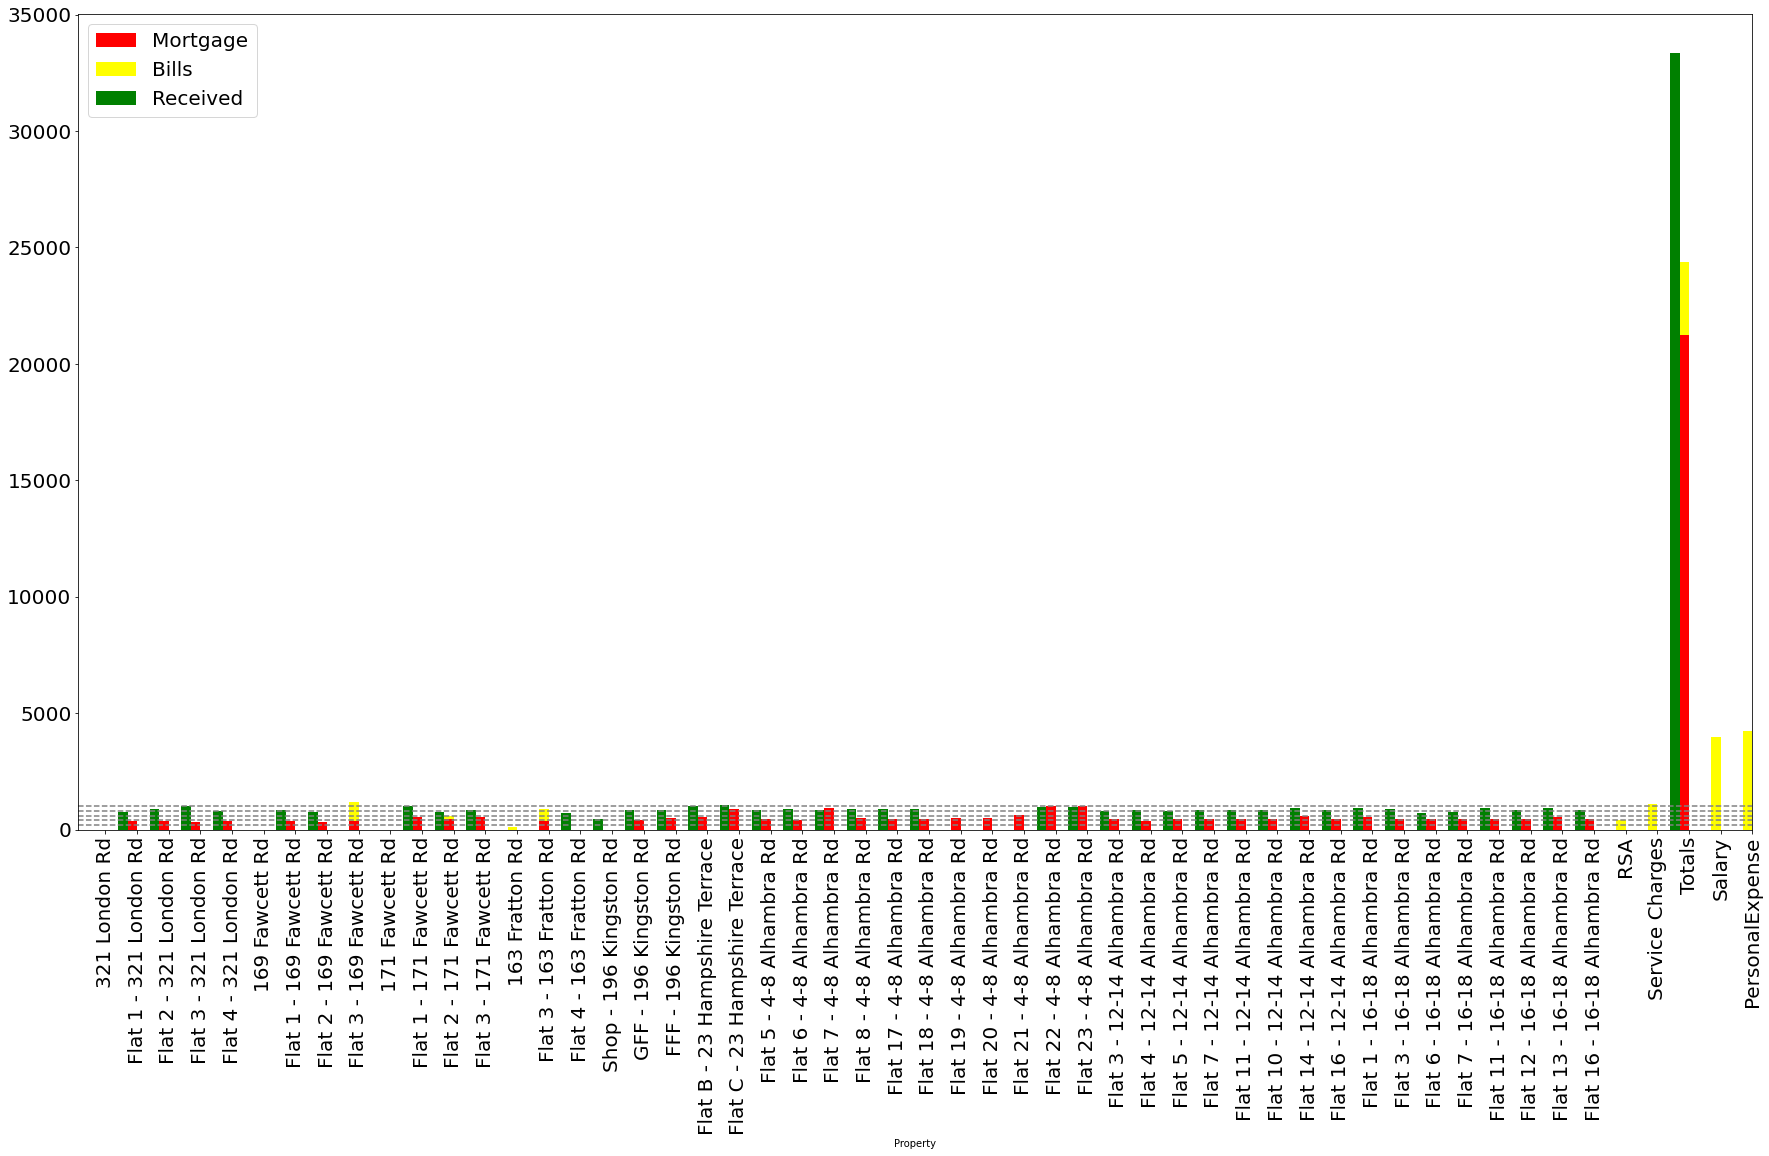

In [4]:
plot_income_expenditure_per_property(dfRs[:-1])

### Net Income Per Property

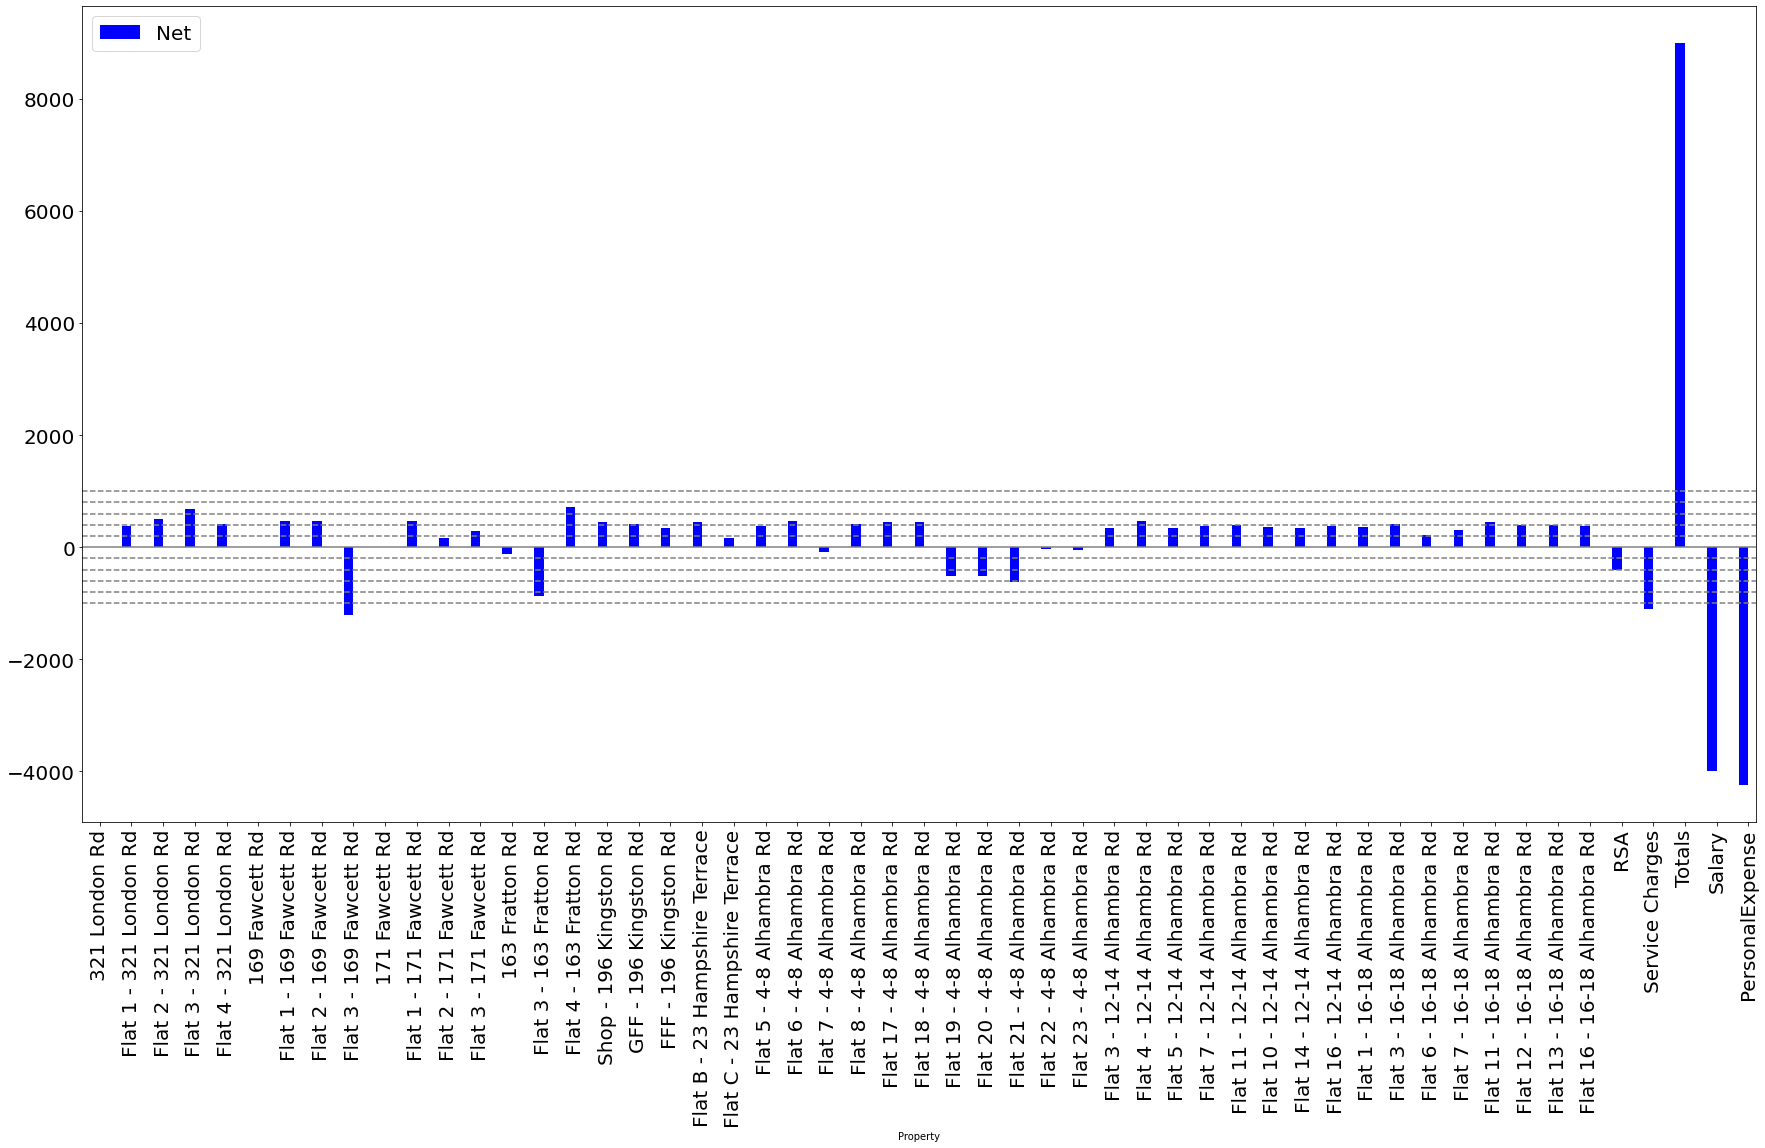

In [5]:
plot_net_income(dfRs[:-1])

### Accounts Check
Check Drawings against expenses

In [6]:
dfAll[(dfAll.Cat=='RegularPayment')|(dfAll.Cat=='PersonalExpense')|(dfAll.Cat=='Hilltop')|(dfAll.Cat=='HMRCDD')|(dfAll.Cat=='Drawings')|(dfAll.Cat=='SchoolFee')].groupby(['Cat']).sum()

,Amount,Description
Cat,,
Hilltop,-300.00,0.0
PersonalExpense,-4568.66,0.0
RegularPayment,-1284.20,0.0


In [7]:
dfAll.groupby(['Account','Cat']).sum().style.apply(custom_style_accounts_cat, axis=1)

#### Mortgage check
Check mortgages refunded from business account

In [8]:
dfMtg=dfAll[((dfAll.Cat=='Mortgage')|(dfAll.Cat=='MortgageRefund'))&(dfAll.Account!='60-83-71 00558156')].groupby(['Account','Cat']).Amount.sum()
dfMtg=dfMtg.reset_index().pivot('Account','Cat')
dfMtg.columns=dfMtg.columns.get_level_values(1)
if('MortgageRefund' not in dfMtg.columns):
    dfMtg['MortgageRefund']=0
dfMtg['Diff']=dfMtg.Mortgage + dfMtg.MortgageRefund
dfMtg

Cat,Mortgage,MortgageRefund,Diff
Account,,,
20-53-97 30728691,-21247.18,0,-21247.18


In [9]:
dfMtg['Diff'].sum()

-21247.180000000004

#### Rent check
Rents going to wrong account

In [10]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='OurRent')]

,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat


In [11]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='OurRent')].groupby(['Cat']).sum()

,Amount,Description
Cat,,


#### Property expense check
Property expenses and service charges taken from 3072 or 6045

In [12]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='PropertyExpense')]

,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat
2026-08-05,20-74-09 60458872,-46.99,Card Purchase,AMAZON* BF9MS6UB5 ON 04 AUG BCC,RSA,NaN,PropertyExpense,Amazon
2026-08-13,20-74-09 60458872,-94.99,Card Purchase,AMAZON UK* AV5YX6J ON 12 AUG BCC,RSA,NaN,PropertyExpense,Amazon
2026-08-14,20-74-09 60458872,-9.74,Card Purchase,amazon.co.uk*GK5EG ON 13 AUG BCC,RSA,NaN,PropertyExpense,Amazon
2026-08-17,20-74-09 60458872,-5.49,Card Purchase,amazon.co.uk*5Z2XM ON 16 AUG BCC,RSA,NaN,PropertyExpense,Amazon
2026-08-25,20-74-09 60458872,-12.49,Card Purchase,Amazon.co.uk*EZ64J ON 24 AUG BCC,RSA,NaN,PropertyExpense,Amazon


In [13]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='PropertyExpense')].groupby(['Cat']).sum()

,Amount,Description
Cat,,
PropertyExpense,-169.7,0.0


In [14]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='ServiceCharge')]

,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat


In [15]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='ServiceCharge')].groupby(['Cat']).sum()

,Amount,Description
Cat,,
